# Shape optimization of a coplanar line: matching it to 50 Ω

**Question.** A conductor-backed coplanar waveguide (CPW) on a 100 µm substrate
(ε_r = 4) has a 50 µm signal strip and 30 µm gaps. Fed and terminated by 50 Ω
lumped ports, it reflects part of the power: its characteristic impedance is not
50 Ω. How should the gaps change along the line so that it reflects as little as
possible between 20 and 60 GHz?

We let gradients find it. The design moves the signal conductor's sidewalls through
`gfem.shape.boundary_morph`: a fixed linear map, built once on the imported mesh,
from normal displacements of the wall's nodes to the node coordinates of a moved
mesh. `jax.grad` differentiates the whole chain, from a few design parameters
through the morph and the driven solve to |S11|². The mesh is never regenerated, so
each step is checked against the mesh quality before it is taken.

In [1]:
import warnings
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import gfem
from gfem import shape

GHz, um = 1e9, 1e-6

## The line

The mesh (written by `tools/make_tutorial_meshes.py`) is a 1.5 mm long line along x.
The metal layer (100 µm < z < 105 µm) holds the signal strip (|y| < 25 µm) and the
ground planes (|y| > 55 µm); both are excluded volumes with perfectly conducting
shells, so the field lives in the substrate and the air. The backside (z = 0) is a
ground plane, the top and the sides absorb. Each port is a pair of lumped elements
across the two gaps at one end, excited from the signal towards the grounds.

In [2]:
mesh = gfem.Mesh.from_gmsh(Path("data/cpw.msh"), length_unit="um")
line = gfem.Model(
    mesh,
    materials={"substrate": gfem.Material(eps_r=4.0), "air": gfem.Material()},
    excluded=("signal_metal", "ground_metal"),
    boundaries=[
        gfem.PEC("signal"),
        gfem.PEC("signal_wall"),
        gfem.PEC("ground"),
        gfem.PEC("backside"),
        gfem.Absorbing("top"),
        gfem.Absorbing("side"),
    ],
    ports=[
        gfem.LumpedPort("p1", ("p1a", "p1b"), ("+y", "-y"), impedance=50.0),
        gfem.LumpedPort("p2", ("p2a", "p2b"), ("+y", "-y"), impedance=50.0),
    ],
)
line

Model(Mesh(495 nodes, 1920 tetrahedra, volumes=['substrate', 'ground_metal', 'air', 'signal_metal'], surfaces=['ends', 'side', 'backside', 'ground', 'top', 'p1b', 'substrate_top', 'signal', 'signal_wall', 'p1a', 'p2b', 'p2a'], length_unit='um')
  materials:
    substrate: Material(eps_r=4.0)
    air: Material()
  excluded (electromagnetic): ground_metal entity 2, signal_metal entity 4 (from 'signal_metal', 'ground_metal')
  boundaries:
    PEC(surface='signal')
    PEC(surface='signal_wall')
    PEC(surface='ground')
    PEC(surface='backside')
    Absorbing(surface='top', order=1)
    Absorbing(surface='side', order=1)
  ports:
    LumpedPort(name='p1', surface=('p1a', 'p1b'), direction=((0.0, 1.0, 0.0), (0.0, -1.0, 0.0)), resistance=None, inductance=None, capacitance=None, impedance=50.0)
    LumpedPort(name='p2', surface=('p2a', 'p2b'), direction=((0.0, 1.0, 0.0), (0.0, -1.0, 0.0)), resistance=None, inductance=None, capacitance=None, impedance=50.0)
  default PMC (electromagnetic pr

## The shape design

`boundary_morph` moves the nodes of one surface, here `"signal_wall"`, the strip's
two sidewalls, each along its outward normal: a positive displacement moves the wall
into the gap, so the strip grows and the gap shrinks. The rest of the mesh follows a
stiffened elastic extension, and the surfaces play roles:

- the port surfaces are held (always: gfem holds the model's ports), so the wall's
  nodes on them are not parameters and the ports keep their geometry;
- `fixed=("ground",)` also holds the ground planes, so the gaps change only through
  the strip;
- every other named surface slides in its own plane: the substrate top, the strip's
  top and bottom, the line's ends and the outer box keep their planes.

One parameter per wall node is far too many to optimize directly, and a jagged wall
would wreck the mesh. Four control values of the half-width change, spaced along
the line and interpolated linearly at each node, make a smooth design.

In [3]:
morph = shape.boundary_morph(line, "signal_wall", fixed=("ground",))
x = morph.points[:, 0]
knots = np.linspace(x.min(), x.max(), 4)


def displacements(q):
    # q: half-width changes in um at the knots -> t: metres at every wall node
    return jnp.interp(x, knots, q) * um


print(f"{morph.n_params} moving nodes on {morph.surface!r}")

28 moving nodes on 'signal_wall'


## The objective

The mean of |S11|² at 20, 40 and 60 GHz, with port 1 excited. A direct solver suits
these small, repeated solves.

In [4]:
problem = gfem.Driven(frequency=(20 * GHz, 40 * GHz, 60 * GHz), excite="p1")
options = gfem.SolverOptions(linear_solver="direct")


def reflection(q):
    designed = line.replace(mesh=morph(displacements(q)))
    s11 = gfem.solve(designed, problem, options=options).s["p1", "p1"]
    return jnp.mean(jnp.abs(s11) ** 2)


value_and_grad = jax.value_and_grad(reflection)
q = jnp.zeros(4)
j, g = value_and_grad(q)
print(f"reflected power {float(j):.4f}, gradient {np.asarray(g)} per um")

reflected power 0.0106, gradient [-0.00095143 -0.00118067 -0.00067009 -0.00032445] per um


## Optimize, accepting steps on mesh quality

A plain normalized gradient descent with a step radius r in µm. A trial step is
taken only if

1. **the mesh stays good**: `gfem.shape.quality` (the scaled Jacobian of every
   tetrahedron) stays above a quarter of each element's imported quality, the
   threshold at which gfem would warn (`MeshQualityWarning`); an inverted element
   would raise `MeshQualityError`;
2. **the objective decreases.**

A rejected step halves r; an accepted one lets it grow again. The quality check runs
before any solve, so a step that would degrade the mesh costs nothing. Called with
concrete values, the morph checks the moved mesh itself: it raises
`MeshQualityError` on an inverted element (and warns below a quarter of the
imported quality), so `acceptable` turns that error into a rejection. The first
trial step below is deliberately wider than the gaps.

In [5]:
q0 = shape.quality(line.mesh)


def acceptable(q):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", gfem.MeshQualityWarning)
            trial_mesh = morph(displacements(q))
    except gfem.MeshQualityError:  # the morph itself refuses inverted elements
        return False
    quality = shape.quality(trial_mesh)
    return bool(jnp.all(quality > shape.WARN_QUALITY_RATIO * q0))


radius, history = 48.0, [float(j)]  # a first step wider than the gap
for iteration in range(12):
    direction = -g / jnp.linalg.norm(g)
    rejected = []
    while radius > 0.05:
        trial = q + radius * direction
        if not acceptable(trial):
            rejected.append("quality")
        elif float(reflection(trial)) >= j:
            rejected.append("no decrease")
        else:
            break
        radius /= 2
    else:
        print("no acceptable step: stop (or remesh and restart, see the recipe)")
        break
    q = trial
    j, g = value_and_grad(q)
    history.append(float(j))
    note = f" (rejected first: {', '.join(rejected)})" if rejected else ""
    print(
        f"{iteration:2d}: reflected power {float(j):.2e}, "
        f"half-width change {np.round(np.asarray(q), 2)} um{note}"
    )
    radius = min(1.5 * radius, 8.0)

 0: reflected power 5.28e-03, half-width change [3.38 4.19 2.38 1.15] um (rejected first: quality, no decrease, no decrease)


 1: reflected power 4.63e-03, half-width change [5.83 0.43 2.45 7.77] um


 2: reflected power 8.95e-04, half-width change [8.16 3.25 2.27 6.17] um (rejected first: no decrease)


 3: reflected power 4.99e-04, half-width change [8.16 3.24 3.21 7.34] um (rejected first: no decrease, no decrease)


 4: reflected power 3.07e-04, half-width change [9.18 3.6  2.91 7.46] um (rejected first: no decrease)


...

 7: reflected power 9.89e-05, half-width change [9.68 3.43 3.31 8.58] um (rejected first: no decrease)


 8: reflected power 7.93e-05, half-width change [9.99 3.57 3.23 8.57] um (rejected first: no decrease)


 9: reflected power 6.83e-05, half-width change [9.98 3.48 3.34 8.79] um (rejected first: no decrease)


10: reflected power 6.22e-05, half-width change [10.16  3.55  3.3   8.78] um (rejected first: no decrease)


11: reflected power 5.88e-05, half-width change [10.15  3.5   3.36  8.9 ] um (rejected first: no decrease)


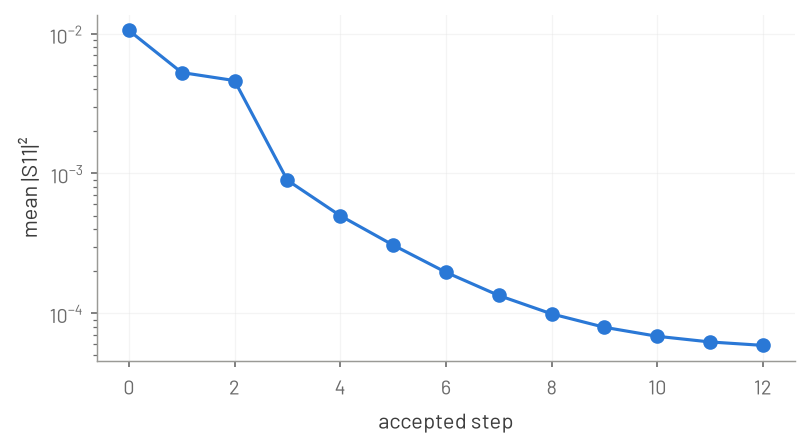

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy(history, marker="o")
ax.set_xlabel("accepted step")
ax.set_ylabel("mean |S11|²")
ax.grid(alpha=0.3);

## The design

The gap along the line: each wall node moved by its displacement along its
normal, into the gap (the ports at both ends keep their 30 µm gap).

worst element quality: 0.65 x its imported quality


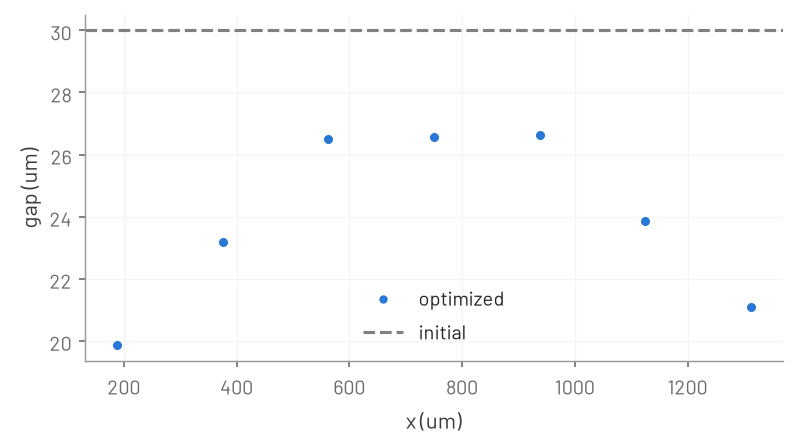

In [7]:
designed = morph(displacements(q))
order = np.argsort(x)
gap = 30.0 - np.asarray(displacements(q)) / um
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x[order] / um, gap[order], ".", label="optimized")
ax.axhline(30.0, color="gray", ls="--", label="initial")
ax.set_xlabel("x (um)")
ax.set_ylabel("gap (um)")
ax.legend()
ax.grid(alpha=0.3)
ratio = np.asarray(shape.quality(designed) / q0)
print(f"worst element quality: {ratio.min():.2f} x its imported quality")

## Trust: the reflection spectrum

A sweep of the initial and the optimized line. The match is broadband: a narrower
gap lowers the line impedance towards 50 Ω at every frequency of the band.

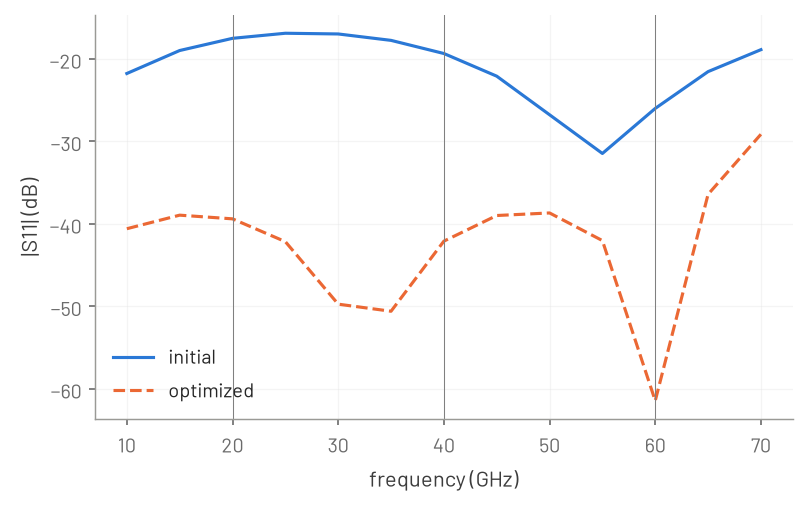

In [8]:
sweep = gfem.Driven(frequency=np.linspace(10, 70, 13) * GHz, excite="p1")
fig, ax = plt.subplots(figsize=(6, 3.5))
for label, mesh_ in (("initial", line.mesh), ("optimized", designed)):
    s = gfem.solve(line.replace(mesh=mesh_), sweep, options=options).s
    s11 = np.asarray(s["p1", "p1"])
    ax.plot(np.asarray(sweep.frequency) / GHz, 20 * np.log10(np.abs(s11)), label=label)
for f in problem.frequency:
    ax.axvline(f / GHz, color="gray", lw=0.5)
ax.set_xlabel("frequency (GHz)")
ax.set_ylabel("|S11| (dB)")
ax.legend()
ax.grid(alpha=0.3);

## When the mesh runs out

This design moved the walls by up to about 10 µm into 30 µm gaps, on cells
15 µm wide. Larger moves eventually degrade the mesh: the quality check above then
rejects every step, and every solve warns. Then remesh at the current geometry with gsim and restart the optimizer
from the current parameters, as the recipe
[remesh and restart](../recipes/remesh-and-restart.md) shows.